# TP Final - Insuficiencia cardíaca: descarga y análisis exploratorio
Dataset: UCI Heart Failure Clinical Records (299 pacientes).
Objetivo: explorar predictores basales de DEATH_EVENT. `time` se excluye de los predictores.

In [0]:
%pip install ucimlrepo==0.0.7 pandas matplotlib seaborn scikit-learn

In [0]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo
from pathlib import Path

heart = fetch_ucirepo(id=519)
X_raw = heart.data.features.copy()
y_raw = heart.data.targets.copy()
df = pd.concat([X_raw, y_raw], axis=1)
df = df.rename(columns={'death_event': 'DEATH_EVENT'})
assert len(df) == 299, f'Cantidad inesperada: {len(df)}'
assert 'DEATH_EVENT' in df.columns
assert df['DEATH_EVENT'].isin([0,1]).all()
print('Dimensiones:', df.shape)
display(df.head())

Dimensiones: (299, 13)


age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
75.0,0,582,0,20,1,265000.0,1.9,130,1,0,4,1
55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
65.0,0,146,0,20,0,162000.0,1.3,129,1,1,7,1
50.0,1,111,0,20,0,210000.0,1.9,137,1,0,7,1
65.0,1,160,1,20,0,327000.0,2.7,116,0,0,8,1


In [0]:
print('Tipos de datos:')
print(df.dtypes.to_string())
print('\nValores faltantes:')
print(df.isna().sum().to_string())
print('\nDuplicados exactos:', df.duplicated().sum())
print('\nDistribución de mortalidad:')
print(df.DEATH_EVENT.value_counts().sort_index().to_string())
print('\nPorcentaje:')
print((df.DEATH_EVENT.value_counts(normalize=True).sort_index()*100).round(2).to_string())
display(df.describe(include='all').T)

Tipos de datos:
age                         float64
anaemia                       int64
creatinine_phosphokinase      int64
diabetes                      int64
ejection_fraction             int64
high_blood_pressure           int64
platelets                   float64
serum_creatinine            float64
serum_sodium                  int64
sex                           int64
smoking                       int64
time                          int64
DEATH_EVENT                   int64

Valores faltantes:
age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
time                        0
DEATH_EVENT                 0

Duplicados exactos: 0

Distribución de mortalidad:
DEATH_EVENT
0    203
1     96

Porcentaje:
DEATH_EVENT

count,mean,std,min,25%,50%,75%,max
299.0,60.83389297658862,11.89480907404447,40.0,51.0,60.0,70.0,95.0
299.0,0.431438127090301,0.4961072681330793,0.0,0.0,0.0,1.0,1.0
299.0,581.8394648829432,970.2878807124362,23.0,116.5,250.0,582.0,7861.0
299.0,0.4180602006688963,0.49406706510360904,0.0,0.0,0.0,1.0,1.0
299.0,38.08361204013378,11.834840741039171,14.0,30.0,38.0,45.0,80.0
299.0,0.3511705685618729,0.47813637906274475,0.0,0.0,0.0,1.0,1.0
299.0,263358.02926421404,97804.2368685983,25100.0,212500.0,262000.0,303500.0,850000.0
299.0,1.3938795986622072,1.0345100640898541,0.5,0.9,1.1,1.4,9.4
299.0,136.62541806020067,4.412477283909235,113.0,134.0,137.0,140.0,148.0
299.0,0.6488294314381271,0.47813637906274475,0.0,0.0,1.0,1.0,1.0


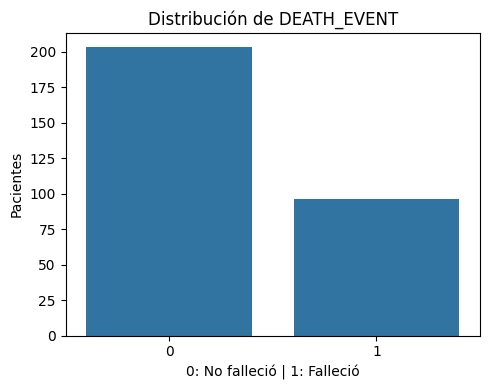

In [0]:
fig, ax = plt.subplots(figsize=(5,4))
sns.countplot(data=df, x='DEATH_EVENT', ax=ax)
ax.set(title='Distribución de DEATH_EVENT', xlabel='0: No falleció | 1: Falleció', ylabel='Pacientes')
plt.tight_layout(); plt.show()

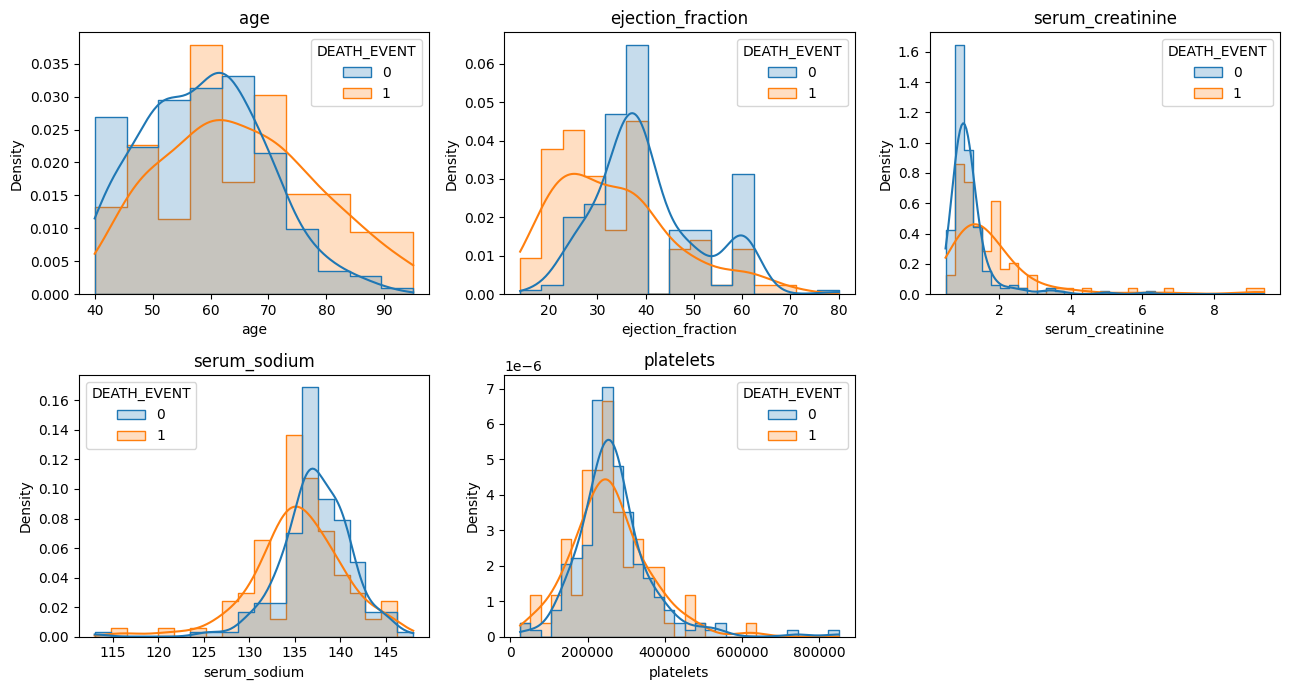

In [0]:
variables = ['age', 'ejection_fraction', 'serum_creatinine', 'serum_sodium', 'platelets']
fig, axes = plt.subplots(2,3,figsize=(13,7))
for ax, col in zip(axes.flat, variables):
    sns.histplot(data=df, x=col, hue='DEATH_EVENT', kde=True, element='step', stat='density', common_norm=False, ax=ax)
    ax.set_title(col)
for ax in axes.flat[len(variables):]: ax.axis('off')
plt.tight_layout(); plt.show()

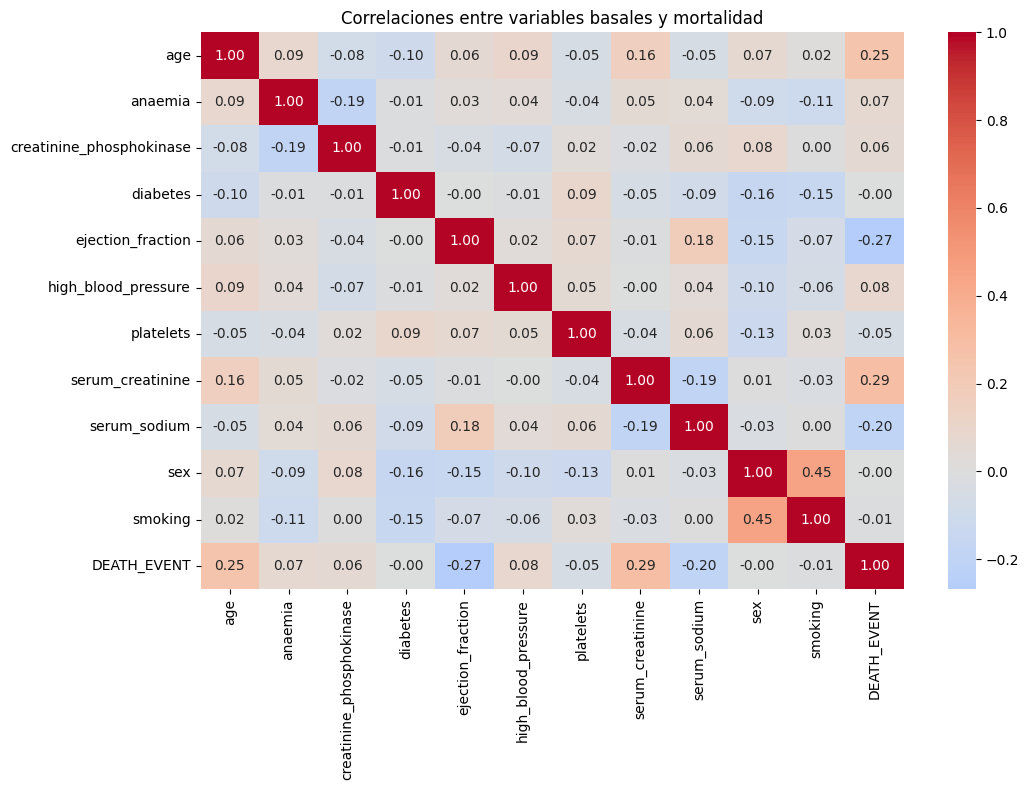

In [0]:
fig, ax = plt.subplots(figsize=(11,8))
sns.heatmap(df.drop(columns=['time'], errors='ignore').corr(numeric_only=True), cmap='coolwarm', center=0, annot=True, fmt='.2f', ax=ax)
ax.set_title('Correlaciones entre variables basales y mortalidad')
plt.tight_layout(); plt.show()

In [0]:
# Solo se excluye `time` del conjunto predictor, no del dataframe descriptivo.
features = df.drop(columns=['DEATH_EVENT','time'], errors='ignore')
target = df['DEATH_EVENT'].astype(int)
assert features.shape[1] == 11, f'Se esperaban 11 predictores basales, hay {features.shape[1]}'
assert not features.isna().any().any(), 'Revisar valores faltantes antes del entrenamiento'
print('Predictores finales:', features.columns.tolist())
print('X:',features.shape,'y:',target.shape)

Predictores finales: ['age', 'anaemia', 'creatinine_phosphokinase', 'diabetes', 'ejection_fraction', 'high_blood_pressure', 'platelets', 'serum_creatinine', 'serum_sodium', 'sex', 'smoking']
X: (299, 11) y: (299,)


In [0]:
BASE_PATH = "/Volumes/workspace/bigdata_drrach/landing/tp_final_heart_failure"

dbutils.fs.mkdirs(BASE_PATH)

# Archivo que utilizarán los notebooks 02 y 04.
df.to_csv(f"{BASE_PATH}/heart_failure.csv", index=False)

# Copia con los predictores y la variable objetivo, sin time.
features.assign(DEATH_EVENT=target).to_csv(
    f"{BASE_PATH}/heart_failure_modelado.csv",
    index=False
)

print("Datos guardados correctamente en:", BASE_PATH)
display(dbutils.fs.ls(BASE_PATH))

Datos guardados correctamente en: /Volumes/workspace/bigdata_drrach/landing/tp_final_heart_failure


path,name,size,modificationTime
dbfs:/Volumes/workspace/bigdata_drrach/landing/tp_final_heart_failure/heart_failure.csv,heart_failure.csv,13493,1792851546000
dbfs:/Volumes/workspace/bigdata_drrach/landing/tp_final_heart_failure/heart_failure_modelado.csv,heart_failure_modelado.csv,12424,1792851547000
dbfs:/Volumes/workspace/bigdata_drrach/landing/tp_final_heart_failure/resultados/,resultados/,0,1792851546392
